In [1]:
import pandas as pd
import matplotlib.pyplot as plt

iot = pd.read_csv("../data/IoT_Sensor_Data_Cleaned.csv")
container = pd.read_csv("../data/Container_Details_Cleaned.csv")

print("Sensor Dataset:", iot.shape)
print("Container Dataset:", container.shape)

Sensor Dataset: (10000, 7)
Container Dataset: (100, 5)


In [2]:
sensor_container_summary = iot.groupby("Container_ID").agg(
    Average_Temperature=("Temperature_C", "mean"),
    Average_Humidity=("Humidity_Percent", "mean"),
    Average_Vibration=("Vibration_Level", "mean"),
    Total_Sensor_Readings=("Sensor_ID", "count")
).reset_index()

display(sensor_container_summary.head())

,Container_ID,Average_Temperature,Average_Humidity,Average_Vibration,Total_Sensor_Readings
0,CONT001,10.9057,90.5151,0.31146,100
1,CONT002,10.7721,89.7703,0.31304,100
2,CONT003,10.2327,90.5598,0.32285,100
3,CONT004,9.2926,89.8810,0.29117,100
4,CONT005,7.3350,89.9559,0.32276,100


In [3]:
combined_data = pd.merge(
    sensor_container_summary,
    container,
    on="Container_ID",
    how="left"
)

print("Combined Dataset Shape:", combined_data.shape)

display(combined_data.head())

Combined Dataset Shape: (100, 9)


,Container_ID,Average_Temperature,Average_Humidity,Average_Vibration,Total_Sensor_Readings,Container_Type,Capacity_KG,Sensor_ID,Refrigeration_Status
0,CONT001,10.9057,90.5151,0.31146,100,Reefer_20ft,18000,SENS001,Operational
1,CONT002,10.7721,89.7703,0.31304,100,Insulated_20ft,14000,SENS002,Operational
2,CONT003,10.2327,90.5598,0.32285,100,Reefer_20ft,18000,SENS003,Operational
3,CONT004,9.2926,89.8810,0.29117,100,Reefer_40ft,26000,SENS004,Operational
4,CONT005,7.3350,89.9559,0.32276,100,Insulated_20ft,14000,SENS005,Operational


In [4]:
print("Total Containers:", len(combined_data))

print(
    "Missing Container Details:",
    combined_data["Container_Type"].isnull().sum()
)

print(
    "Missing Refrigeration Status:",
    combined_data["Refrigeration_Status"].isnull().sum()
)

Total Containers: 100
Missing Container Details: 0
Missing Refrigeration Status: 0


In [5]:
type_sensor_summary = combined_data.groupby("Container_Type").agg(
    Average_Temperature=("Average_Temperature", "mean"),
    Average_Humidity=("Average_Humidity", "mean"),
    Average_Vibration=("Average_Vibration", "mean"),
    Total_Containers=("Container_ID", "count")
)

display(type_sensor_summary.round(2))

,Average_Temperature,Average_Humidity,Average_Vibration,Total_Containers
Container_Type,,,,
Insulated_20ft,9.46,89.89,0.3,34
Reefer_20ft,9.69,89.76,0.3,38
Reefer_40ft,9.99,89.81,0.3,28


In [6]:
refrigeration_sensor_summary = combined_data.groupby(
    "Refrigeration_Status"
).agg(
    Average_Temperature=("Average_Temperature", "mean"),
    Average_Humidity=("Average_Humidity", "mean"),
    Average_Vibration=("Average_Vibration", "mean"),
    Total_Containers=("Container_ID", "count")
)

display(refrigeration_sensor_summary.round(2))

,Average_Temperature,Average_Humidity,Average_Vibration,Total_Containers
Refrigeration_Status,,,,
Intermittent,9.66,89.67,0.31,5
Operational,9.70,89.82,0.30,95


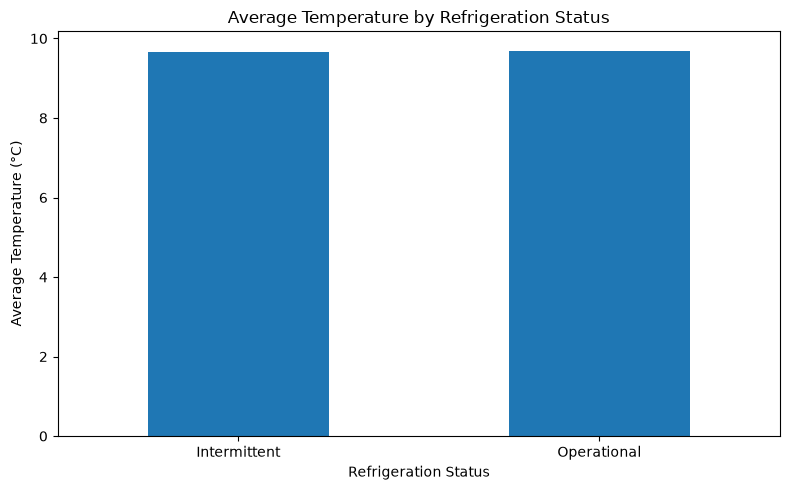

In [7]:
refrigeration_sensor_summary["Average_Temperature"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Average Temperature by Refrigeration Status")
plt.xlabel("Refrigeration Status")
plt.ylabel("Average Temperature (°C)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

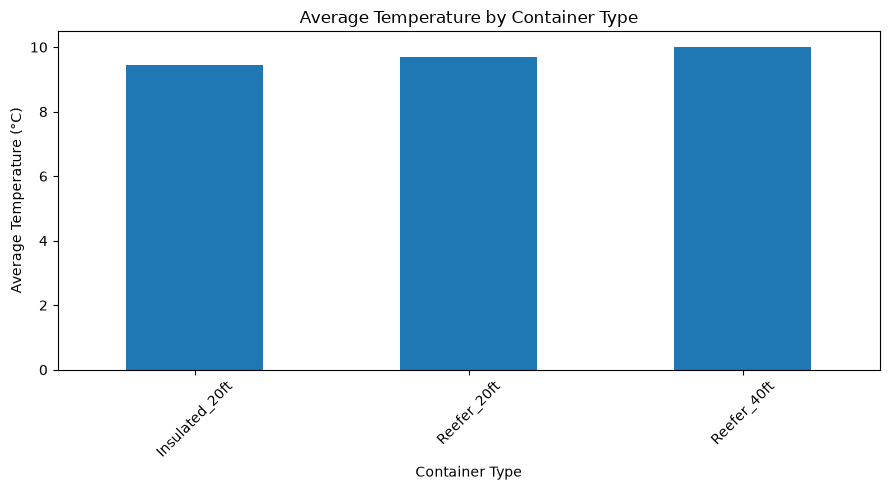

In [8]:
type_sensor_summary["Average_Temperature"].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Average Temperature by Container Type")
plt.xlabel("Container Type")
plt.ylabel("Average Temperature (°C)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [9]:
combined_data.to_csv(
    "../outputs/sensor_container_combined.csv",
    index=False
)

type_sensor_summary.to_csv(
    "../outputs/container_type_sensor_summary.csv"
)

refrigeration_sensor_summary.to_csv(
    "../outputs/refrigeration_sensor_summary.csv"
)

print("All integration files saved successfully!")

All integration files saved successfully!
